# 03 — Modelado, evaluación y análisis (P2)

Predicción de mortalidad hospitalaria (`hospdead = 1`) en SUPPORT2.

Este notebook cubre los puntos de la guía P2:

| Requisito (Guía §2.2 / §3) | Sección |
|---|---|
| Baseline | 2, 5 |
| ≥ 2 modelos comparados | 3, 5 |
| Diseño experimental, CV y ajuste de hiperparámetros | 3, 4 |
| Métricas apropiadas y justificadas | 4, 5 |
| Resultados con tablas y visualizaciones | 5–6 |
| Pregunta de investigación (demográficas vs. fisiológicas) | 7 |
| Interpretación e importancia de variables | 8 |
| Análisis de errores, sesgo y limitaciones | 9–10 |

Todo el cómputo pesado vive en `scripts/run_p2.py` (reproducible por línea de comandos);
este notebook lo documenta, muestra los resultados y los verifica.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "preprocessing.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

from preprocessing import FEATURE_GROUPS, get_feature_set, load_data
from src.evaluation import classification_metrics

pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"

# Cambiar a True para re-ejecutar todo el experimento (~minutos).
RUN_EXPERIMENT = False
# Los modelos serializados (results/models/) no se versionan en git; si faltan
# (p. ej. tras clonar el repositorio) se regenera todo el experimento.
if (RUN_EXPERIMENT or not (TABLES / "p2_test_metrics.csv").exists()
        or not any((ROOT / "results" / "models").glob("*.joblib"))):
    import run_p2
    run_p2.main()

## 1. Datos y particiones

Se reutilizan sin cambios las particiones de P1 (80/20 estratificado, semilla 42)
y las 27 variables seleccionadas tras excluir variables con fuga de información
(`death`, `slos`, `d.time`, costos, `sps`, `aps`, `surv*`, `prg*`, `dnr*`, …) y
con más de 50 % de faltantes en entrenamiento (`adlp`, `urine`).

In [2]:
X_train, X_test, y_train, y_test = load_data()
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Prevalencia hospdead=1 — train {y_train.mean():.4f} | test {y_test.mean():.4f}")
pd.DataFrame({g: [", ".join(c)] for g, c in FEATURE_GROUPS.items()}, index=["variables"]).T

Train: (7284, 27) | Test: (1821, 27)
Prevalencia hospdead=1 — train 0.2592 | test 0.2592


,variables
demographic,"age, sex, race, income, edu"
clinical,"dzgroup, dzclass, num.co, diabetes, dementia, ca, adls, hday"
physiological,"scoma, meanbp, wblc, hrt, resp, temp, pafi, alb, bili, crea, sod, ph, glucose, bun"


## 2. Preprocesamiento y prevención de fuga

* **Numéricas**: imputación por mediana (robusta a outliers clínicos reales, que
  no se eliminan). Opcionalmente, indicadores de faltante (`add_indicator`) — en
  SUPPORT la ausencia de un laboratorio suele significar que no se solicitó, lo que
  puede ser informativo. Si se usan o no se decide por CV.
* **Categóricas**: imputación por moda + one-hot (`handle_unknown="ignore"`).
* **Escalamiento** $x'_j=(x_j-\mu_j)/\sigma_j$ solo para la regresión logística
  (la penalización $\lambda\lVert w\rVert$ depende de la escala); los árboles son
  invariantes a transformaciones monótonas.
* Todo el preprocesador está **dentro del `Pipeline`**, de modo que en cada fold
  se ajusta solo con los datos de entrenamiento de ese fold y el test nunca
  interviene. La celda siguiente lo verifica sobre el modelo final guardado.

In [3]:
meta = json.loads((ROOT / "results" / "p2_run_metadata.json").read_text(encoding="utf-8"))
best_name = meta["selected_model"]
model = joblib.load(ROOT / "results" / "models" / f"{best_name}__full.joblib")
num_pipe = model.named_steps["preprocessor"].named_transformers_["numeric"]
num_cols = model.named_steps["preprocessor"].transformers_[0][2]
stats = num_pipe.named_steps["imputer"].statistics_
assert np.allclose(stats, X_train[num_cols].median().values), "El imputador no se ajustó solo con train"
print("OK: medianas del imputador = medianas de entrenamiento.")
meta

OK: medianas del imputador = medianas de entrenamiento.


{'quick': False,
 'random_state': 42,
 'cv': 'StratifiedKFold(n_splits=5, shuffle=True, random_state=42)',
 'selection_metric': 'roc_auc',
 'threshold_rule': 'max F1 on out-of-fold train predictions',
 'selected_model': 'gboost',
 'selected_threshold': 0.29338197606658095,
 'split_sha256_16': '19e4e3f52edfbd78',
 'n_train': 7284,
 'n_test': 1821,
 'feature_sets': {'demographic': ['age', 'sex', 'edu', 'income', 'race'],
  'demographic+physiological': ['age',
   'sex',
   'edu',
   'income',
   'scoma',
   'race',
   'meanbp',
   'wblc',
   'hrt',
   'resp',
   'temp',
   'pafi',
   'alb',
   'bili',
   'crea',
   'sod',
   'ph',
   'glucose',
   'bun'],
  'full': ['age',
   'sex',
   'dzgroup',
   'dzclass',
   'num.co',
   'edu',
   'income',
   'scoma',
   'race',
   'hday',
   'diabetes',
   'dementia',
   'ca',
   'meanbp',
   'wblc',
   'hrt',
   'resp',
   'temp',
   'pafi',
   'alb',
   'bili',
   'crea',
   'sod',
   'ph',
   'glucose',
   'bun',
   'adls']},
 'python': '3.11.8'

## 3. Modelos y espacios de búsqueda

| Modelo | Formulación (diapositivas) | Hiperparámetros explorados |
|---|---|---|
| Dummy (prior) — baseline P1 | $p = \hat P(y=1)$ constante | — |
| Regresión logística | $p=\sigma(w^Tx+b)$, mín. log-loss $+\lambda\Omega(w)$, $\Omega\in\{\lVert w\rVert_2^2,\lVert w\rVert_1\}$, $C=1/\lambda$ | $C\in[10^{-3},10^2]$ (log), ridge/lasso, `class_weight` |
| Árbol de decisión (CART) | Gini $1-\sum_k\hat p_{mk}^2$ / entropía; poda $R_\alpha(T)=R(T)+\alpha\lvert T\rvert$ | criterio, `max_depth`, `min_samples_leaf`, `ccp_alpha`, `class_weight` |
| Random Forest | bagging + submuestreo de variables; $\bar p(x)=\frac1B\sum_b P_b(y=1\mid x)$ | `max_features`, `max_depth`, `min_samples_leaf`, `class_weight` (B = 500) |
| Gradient Boosting | $F_t(x)=F_{t-1}(x)+\eta\,h_t(x)$, pérdida log-loss | $\eta$, nº de iteraciones, hojas, `min_samples_leaf`, regularización L2 |

Todos los modelos comparten además el hiperparámetro `add_indicator` del imputador.

**Elección de la familia de modelos.** La regresión logística es el modelo
interpretable de referencia (odds ratios). El árbol es interpretable pero de alta
varianza; Random Forest y Gradient Boosting reducen varianza (bagging) o sesgo
(boosting) y capturan no linealidades e interacciones entre variables
fisiológicas que la logística no modela.

## 4. Diseño experimental

* **Búsqueda**: `RandomizedSearchCV` (20–40 candidatos por modelo) con
  `StratifiedKFold(k=5, shuffle, semilla 42)` **solo sobre entrenamiento**:
  $CV(M,\theta)=\frac1K\sum_k \text{Score}_{k}(M,\theta)$.
* **Métrica de selección**: ROC-AUC (no depende del umbral y es insensible a la
  prevalencia de 26 %). Se registran además AP (PR-AUC), F1, recall, precision,
  accuracy y log-loss.
* **Umbral** $\hat y=\mathbf 1[p\ge\tau]$: $\tau=0.5$ no es un umbral clínico
  validado. Se elige $\tau$ que maximiza F1 sobre predicciones *out-of-fold* de
  entrenamiento; nunca con test (regla RB-09). Se reportan ambos umbrales.
* **Modelo final**: el de mayor ROC-AUC media en CV con todas las variables.
* **Test**: se evalúa una única vez al final; IC 95 % por bootstrap (1000 réplicas)
  y diferencias pareadas entre modelos.

In [4]:
cv = pd.read_csv(TABLES / "p2_cv_results.csv")
cols = ["model", "feature_set", "cv_roc_auc_mean", "cv_roc_auc_std", "train_roc_auc",
        "cv_average_precision_mean", "cv_f1_mean", "cv_recall_mean", "cv_neg_log_loss_mean",
        "threshold", "fit_seconds"]
cv[cols].sort_values(["feature_set", "cv_roc_auc_mean"], ascending=[True, False])

,model,feature_set,cv_roc_auc_mean,cv_roc_auc_std,train_roc_auc,cv_average_precision_mean,cv_f1_mean,cv_recall_mean,cv_neg_log_loss_mean,threshold,fit_seconds
7,gboost,demographic,0.5755,0.0084,0.6501,0.3290,0.0259,0.0132,-0.5646,0.2030,15.2
5,logreg,demographic,0.5698,0.0109,0.5763,0.3307,0.0021,0.0011,-0.5646,0.2017,8.0
8,gboost,demographic+physiological,0.7846,0.0070,0.8421,0.6094,0.4531,0.3321,-0.4653,0.2764,24.9
6,logreg,demographic+physiological,0.7511,0.0111,0.7607,0.5581,0.5344,0.6012,-0.5828,0.5029,22.4
4,gboost,full,0.8235,0.0079,0.9474,0.6465,0.5211,0.4290,-0.4323,0.2934,35.6
3,rf,full,0.8184,0.0098,0.9036,0.6265,0.5961,0.7214,-0.4950,0.5433,49.6
1,logreg,full,0.8044,0.0074,0.8144,0.6090,0.5809,0.7145,-0.5372,0.5309,48.5
2,tree,full,0.7813,0.0120,0.8187,0.5581,0.4476,0.3512,-0.4741,0.3125,3.7
0,dummy,full,0.5000,0.0000,0.5000,0.2592,0.0000,0.0000,-0.5722,0.5000,2.4


In [5]:
print("Mejores hiperparámetros (todas las variables):")
for _, r in cv[cv.feature_set == "full"].iterrows():
    print(f"- {r.model}: {r.best_params}")

Mejores hiperparámetros (todas las variables):
- dummy: {"classifier__strategy": "prior"}
- logreg: {"classifier__C": 1.1462107403425035, "classifier__class_weight": "balanced", "classifier__l1_ratio": 1.0, "preprocessor__numeric__imputer__add_indicator": true}
- tree: {"classifier__ccp_alpha": 1.3783237455007187e-05, "classifier__class_weight": null, "classifier__criterion": "gini", "classifier__max_depth": 8, "classifier__min_samples_leaf": 77, "preprocessor__numeric__imputer__add_indicator": false}
- rf: {"classifier__class_weight": "balanced_subsample", "classifier__max_depth": null, "classifier__max_features": 0.3, "classifier__min_samples_leaf": 20, "preprocessor__numeric__imputer__add_indicator": true}
- gboost: {"classifier__l2_regularization": 1.2487080962675865, "classifier__learning_rate": 0.024245340796188324, "classifier__max_features": 0.5, "classifier__max_iter": 233, "classifier__max_leaf_nodes": 35, "classifier__min_samples_leaf": 37, "preprocessor__numeric__imputer__a

La diferencia `train_roc_auc − cv_roc_auc_mean` es un indicador de
sobreajuste (varianza). La curva de validación del árbol ilustra el compromiso
sesgo-varianza al aumentar la profundidad sin poda:

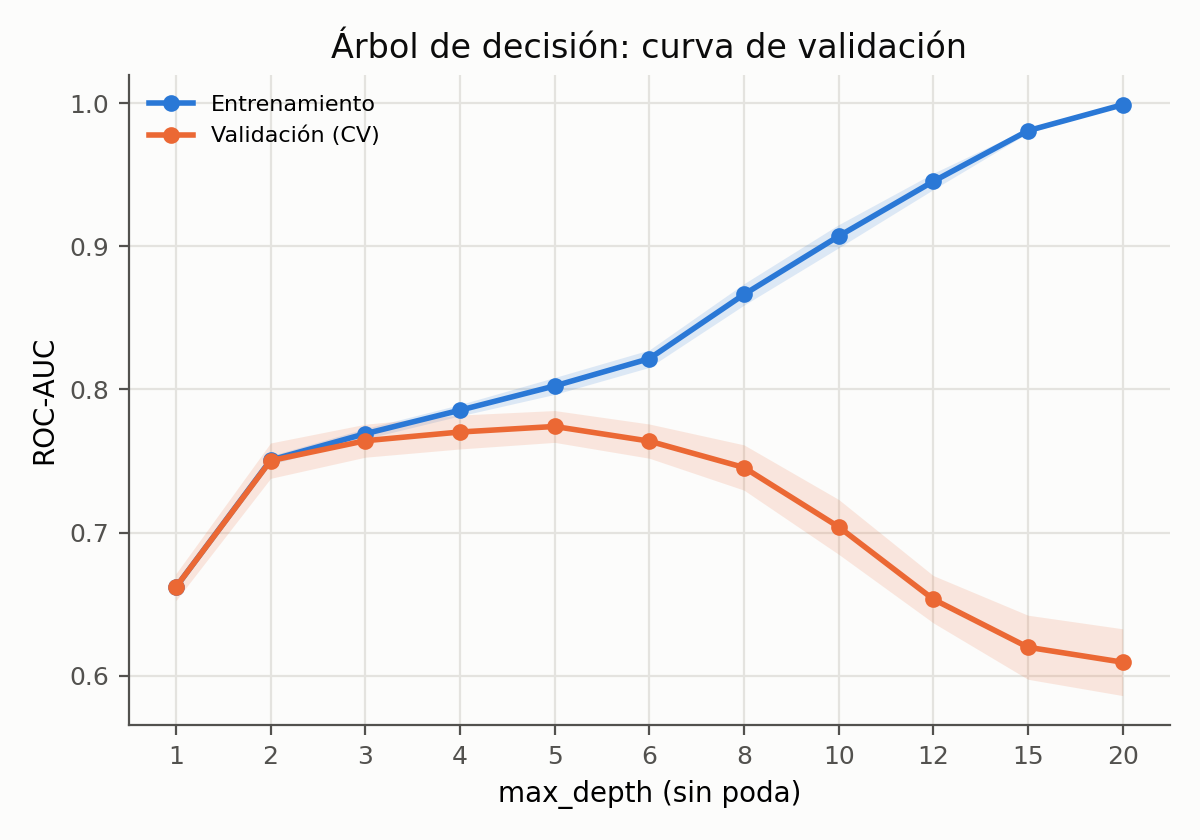

,max_depth,train_auc_mean,train_auc_std,cv_auc_mean,cv_auc_std
0,1,0.6618,0.0024,0.6618,0.0094
1,2,0.7506,0.0030,0.7502,0.0124
2,3,0.7691,0.0036,0.7642,0.0115
3,4,0.7855,0.0040,0.7703,0.0118
4,5,0.8024,0.0059,0.7741,0.0111
5,6,0.8215,0.0061,0.7639,0.0120
6,8,0.8664,0.0075,0.7455,0.0158
7,10,0.9071,0.0081,0.7040,0.0192
8,12,0.9454,0.0057,0.6534,0.0165
9,15,0.9808,0.0016,0.6198,0.0224


In [6]:
display(Image(FIGURES / "p2_tree_validation_curve.png", width=520))
pd.read_csv(TABLES / "p2_tree_validation_curve.csv")

## 5. Resultados en prueba

In [7]:
test = pd.read_csv(TABLES / "p2_test_metrics.csv")
show = ["model", "threshold_rule", "threshold", "accuracy", "precision", "recall",
        "specificity", "f1", "roc_auc", "average_precision", "brier", "TP", "FP", "FN", "TN"]
test[test.feature_set == "full"][show]

,model,threshold_rule,threshold,accuracy,precision,recall,specificity,f1,roc_auc,average_precision,brier,TP,FP,FN,TN
0,dummy,0.5,0.5000,0.7408,0.0000,0.0000,1.0000,0.0000,0.5000,0.2592,0.1920,0,0,472,1349
1,logreg,0.5,0.5000,0.7518,0.5149,0.7309,0.7591,0.6042,0.8199,0.6294,0.1710,345,325,127,1024
2,logreg,cv_f1,0.5309,0.7672,0.5395,0.6949,0.7924,0.6074,0.8199,0.6294,0.1710,328,280,144,1069
3,tree,0.5,0.5000,0.7803,0.6192,0.3962,0.9148,0.4832,0.7992,0.5746,0.1488,187,115,285,1234
4,tree,cv_f1,0.3125,0.7529,0.5183,0.6610,0.7850,0.5810,0.7992,0.5746,0.1488,312,290,160,1059
5,rf,0.5,0.5000,0.7501,0.5129,0.7140,0.7628,0.5970,0.8322,0.6412,0.1596,337,320,135,1029
6,rf,cv_f1,0.5433,0.7776,0.5589,0.6737,0.8139,0.6110,0.8322,0.6412,0.1596,318,251,154,1098
7,gboost,0.5,0.5000,0.8040,0.6898,0.4428,0.9303,0.5394,0.8341,0.6552,0.1365,209,94,263,1255
8,gboost,cv_f1,0.2934,0.7650,0.5355,0.7034,0.7865,0.6081,0.8341,0.6552,0.1365,332,288,140,1061


In [8]:
boot = pd.read_csv(TABLES / "p2_bootstrap_vs_best.csv")
boot[[c for c in boot.columns if not c.startswith("average_precision_diff")]]

,model,roc_auc,roc_auc_ci_low,roc_auc_ci_high,roc_auc_diff_vs_gboost|full,roc_auc_diff_ci_low,roc_auc_diff_ci_high,average_precision,average_precision_ci_low,average_precision_ci_high
0,logreg|full,0.8199,0.7995,0.8418,-0.0145,-0.0244,-0.0047,0.6294,0.5834,0.6750
1,tree|full,0.7992,0.7780,0.8213,-0.0351,-0.0487,-0.0203,0.5746,0.5273,0.6259
2,rf|full,0.8322,0.8128,0.8531,-0.0019,-0.0082,0.0044,0.6412,0.5949,0.6876
3,gboost|full,0.8341,0.8145,0.8544,NaN,NaN,NaN,0.6552,0.6114,0.7000
4,logreg|demographic,0.5666,0.5330,0.5951,-0.2689,-0.3043,-0.2362,0.3130,0.2793,0.3507
5,logreg|demographic+physiological,0.7577,0.7328,0.7833,-0.0768,-0.0973,-0.0564,0.5800,0.5370,0.6250
6,gboost|demographic,0.5692,0.5356,0.5981,-0.2665,-0.3022,-0.2338,0.3284,0.2929,0.3699
7,gboost|demographic+physiological,0.7965,0.7746,0.8195,-0.0378,-0.0545,-0.0212,0.6182,0.5732,0.6624


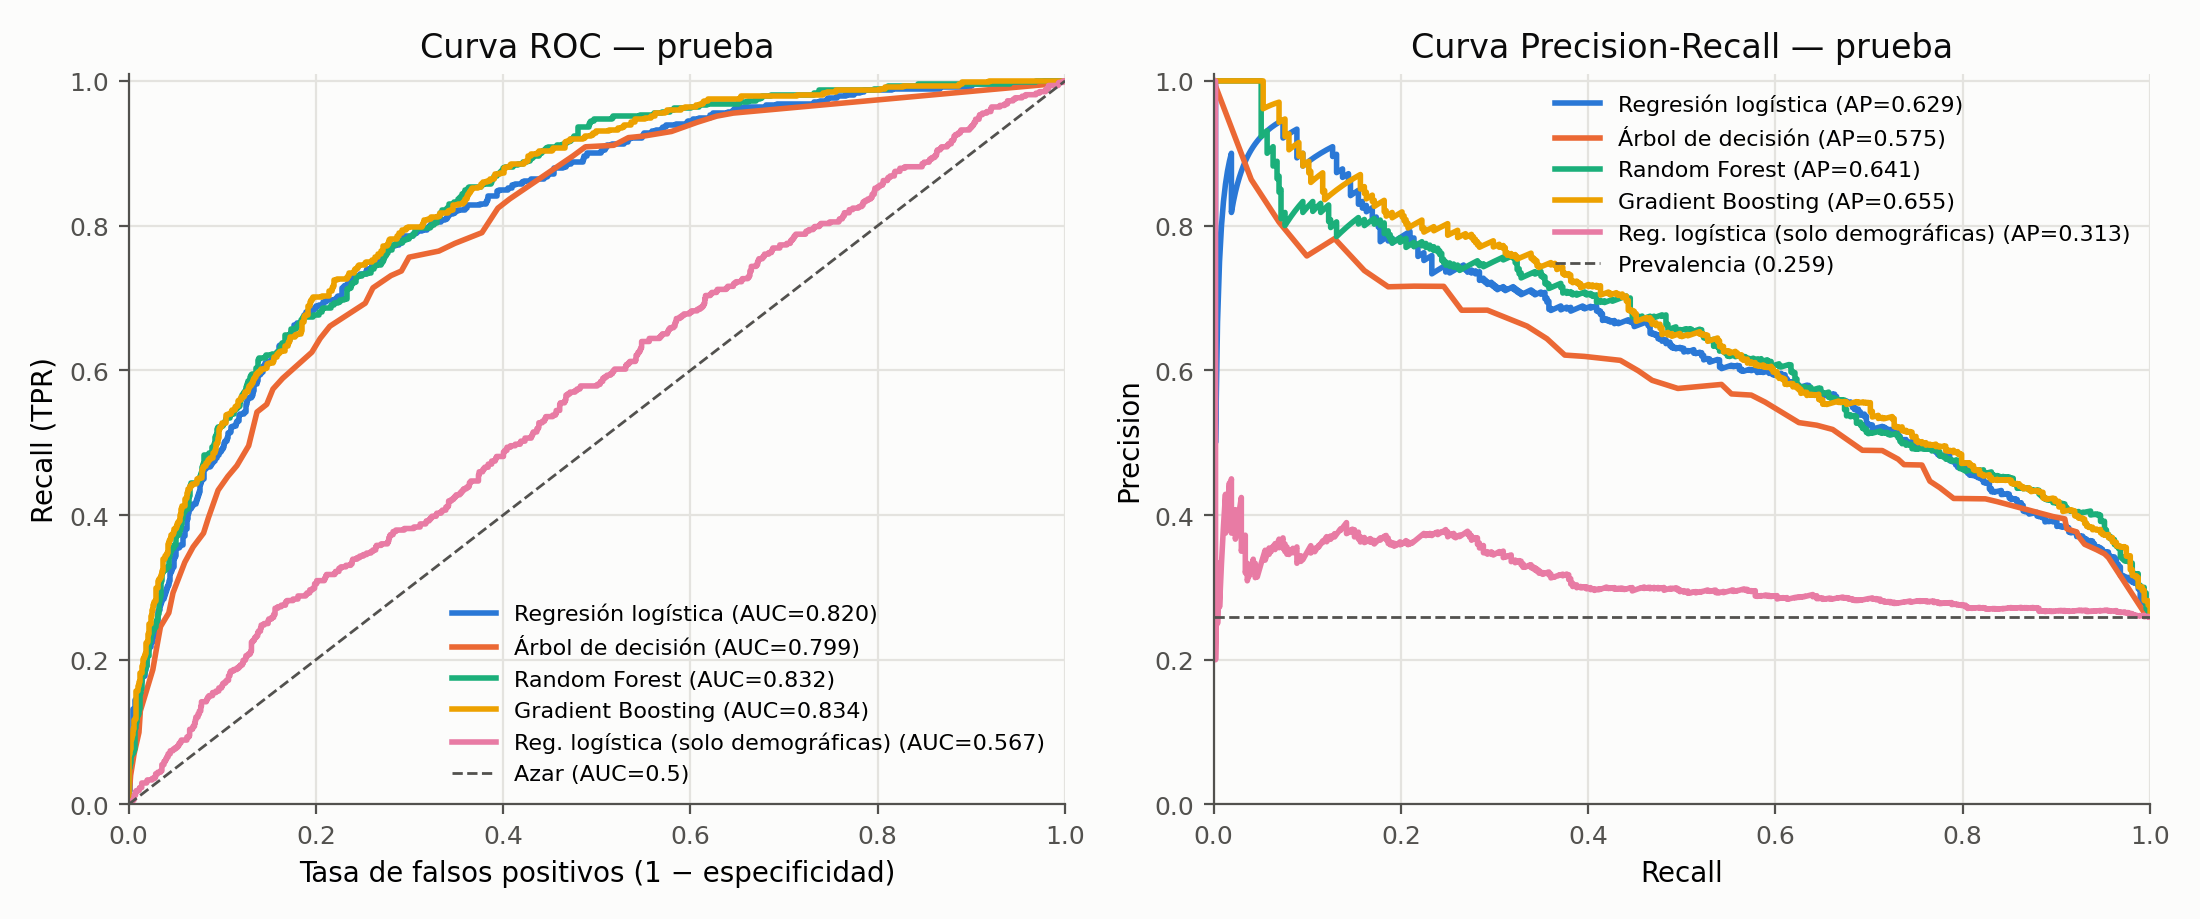

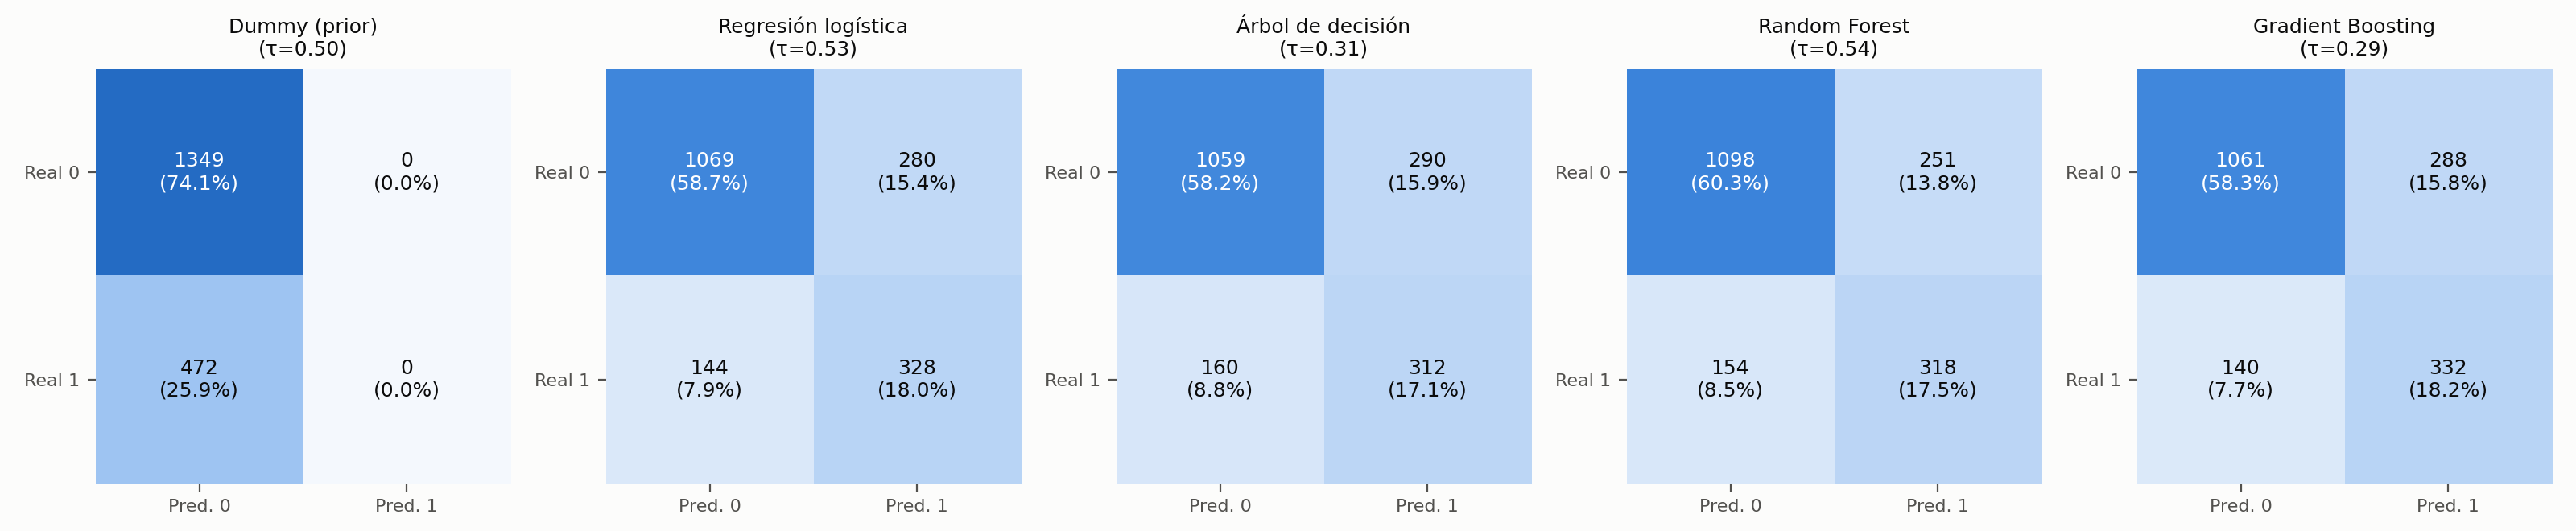

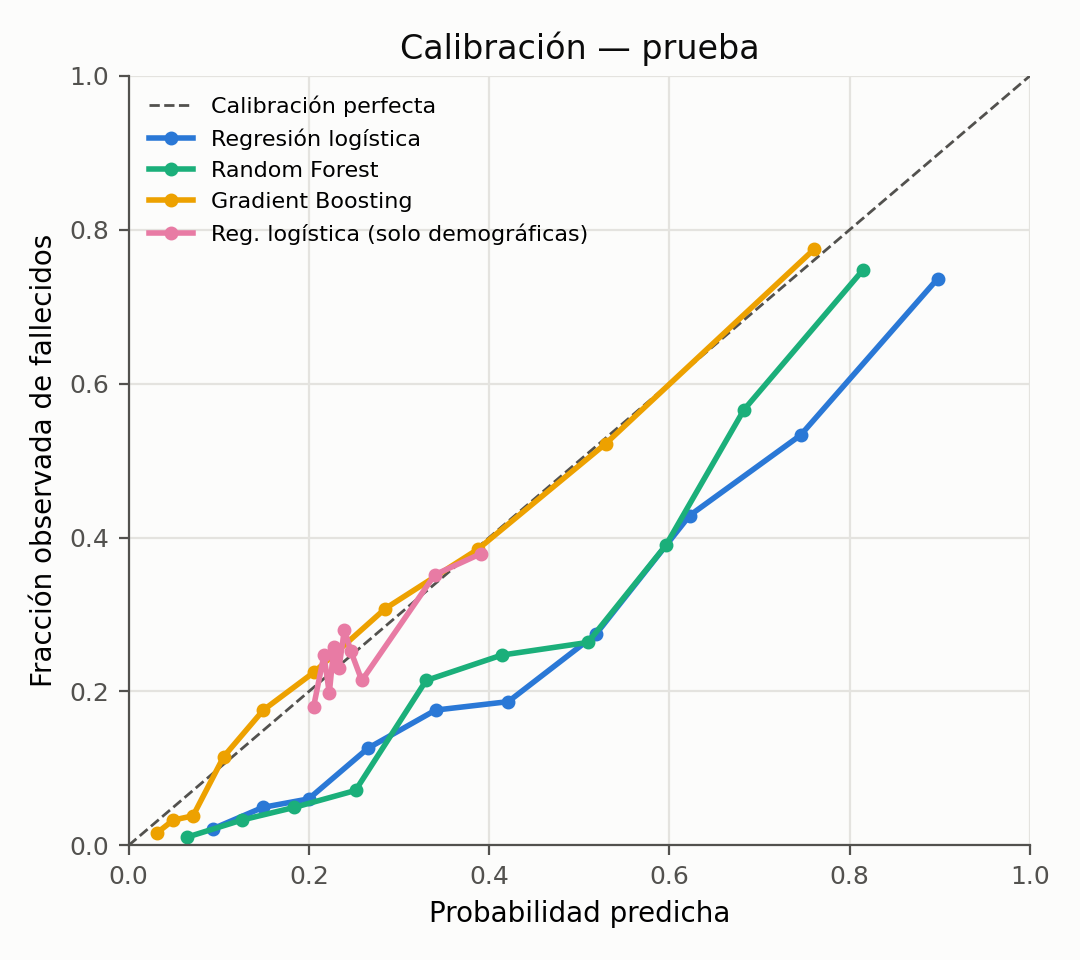

In [9]:
display(Image(FIGURES / "p2_roc_pr_curves.png", width=900))
display(Image(FIGURES / "p2_confusion_matrices.png", width=900))
display(Image(FIGURES / "p2_calibration.png", width=480))

## 6. Verificación independiente

Se recalculan las métricas a partir de las
probabilidades guardadas en `p2_test_predictions.csv` y se comparan con la tabla.

In [10]:
pred = pd.read_csv(TABLES / "p2_test_predictions.csv")
assert (pred["original_index"].values == X_test.index.values).all()
for _, r in test.iterrows():
    m = classification_metrics(pred["y_true"], pred[f"proba_{r.model}_{r.feature_set}"], r.threshold)
    for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]:
        assert abs(m[k] - r[k]) < 1e-12, (r.model, k)
print("OK: las", len(test), "filas de métricas se reproducen desde las predicciones.")

OK: las 17 filas de métricas se reproducen desde las predicciones.


## 7. Pregunta de investigación: ¿variables fisiológicas vs. demográficas?

Se repite la búsqueda completa para regresión logística y Gradient Boosting con
tres conjuntos: solo demográficas (edad, sexo, raza, ingreso, educación),
demográficas + fisiológicas (día 3), y todas (añade diagnóstico, comorbilidades
y estado funcional). La diferencia de AUC se estima con bootstrap pareado sobre
los mismos pacientes de prueba.

In [11]:
abl = test[(test.threshold_rule == "0.5") & test.model.isin(["logreg", "gboost"])]
order = {"demographic": 0, "demographic+physiological": 1, "full": 2}
abl = abl.assign(o=abl.feature_set.map(order)).sort_values(["model", "o"])
display(abl[["model", "feature_set", "roc_auc", "average_precision", "brier"]])

bd = pd.read_csv(TABLES / "p2_bootstrap_vs_demographic.csv")
bd[["model", "roc_auc", "roc_auc_ci_low", "roc_auc_ci_high",
    "roc_auc_diff_vs_logreg|demographic", "roc_auc_diff_ci_low", "roc_auc_diff_ci_high"]]

,model,feature_set,roc_auc,average_precision,brier
13,gboost,demographic,0.5692,0.3284,0.1891
15,gboost,demographic+physiological,0.7965,0.6182,0.1470
7,gboost,full,0.8341,0.6552,0.1365
9,logreg,demographic,0.5666,0.3130,0.1892
11,logreg,demographic+physiological,0.7577,0.5800,0.1907
1,logreg,full,0.8199,0.6294,0.1710


,model,roc_auc,roc_auc_ci_low,roc_auc_ci_high,roc_auc_diff_vs_logreg|demographic,roc_auc_diff_ci_low,roc_auc_diff_ci_high
0,logreg|full,0.8199,0.7995,0.8418,0.2544,0.2216,0.2902
1,tree|full,0.7992,0.7780,0.8213,0.2338,0.1999,0.2725
2,rf|full,0.8322,0.8128,0.8531,0.2670,0.2331,0.3036
3,gboost|full,0.8341,0.8145,0.8544,0.2689,0.2362,0.3043
4,logreg|demographic,0.5666,0.5330,0.5951,NaN,NaN,NaN
5,logreg|demographic+physiological,0.7577,0.7328,0.7833,0.1921,0.1606,0.2269
6,gboost|demographic,0.5692,0.5356,0.5981,0.0024,-0.0194,0.0240
7,gboost|demographic+physiological,0.7965,0.7746,0.8195,0.2311,0.1981,0.2683


## 8. Interpretación

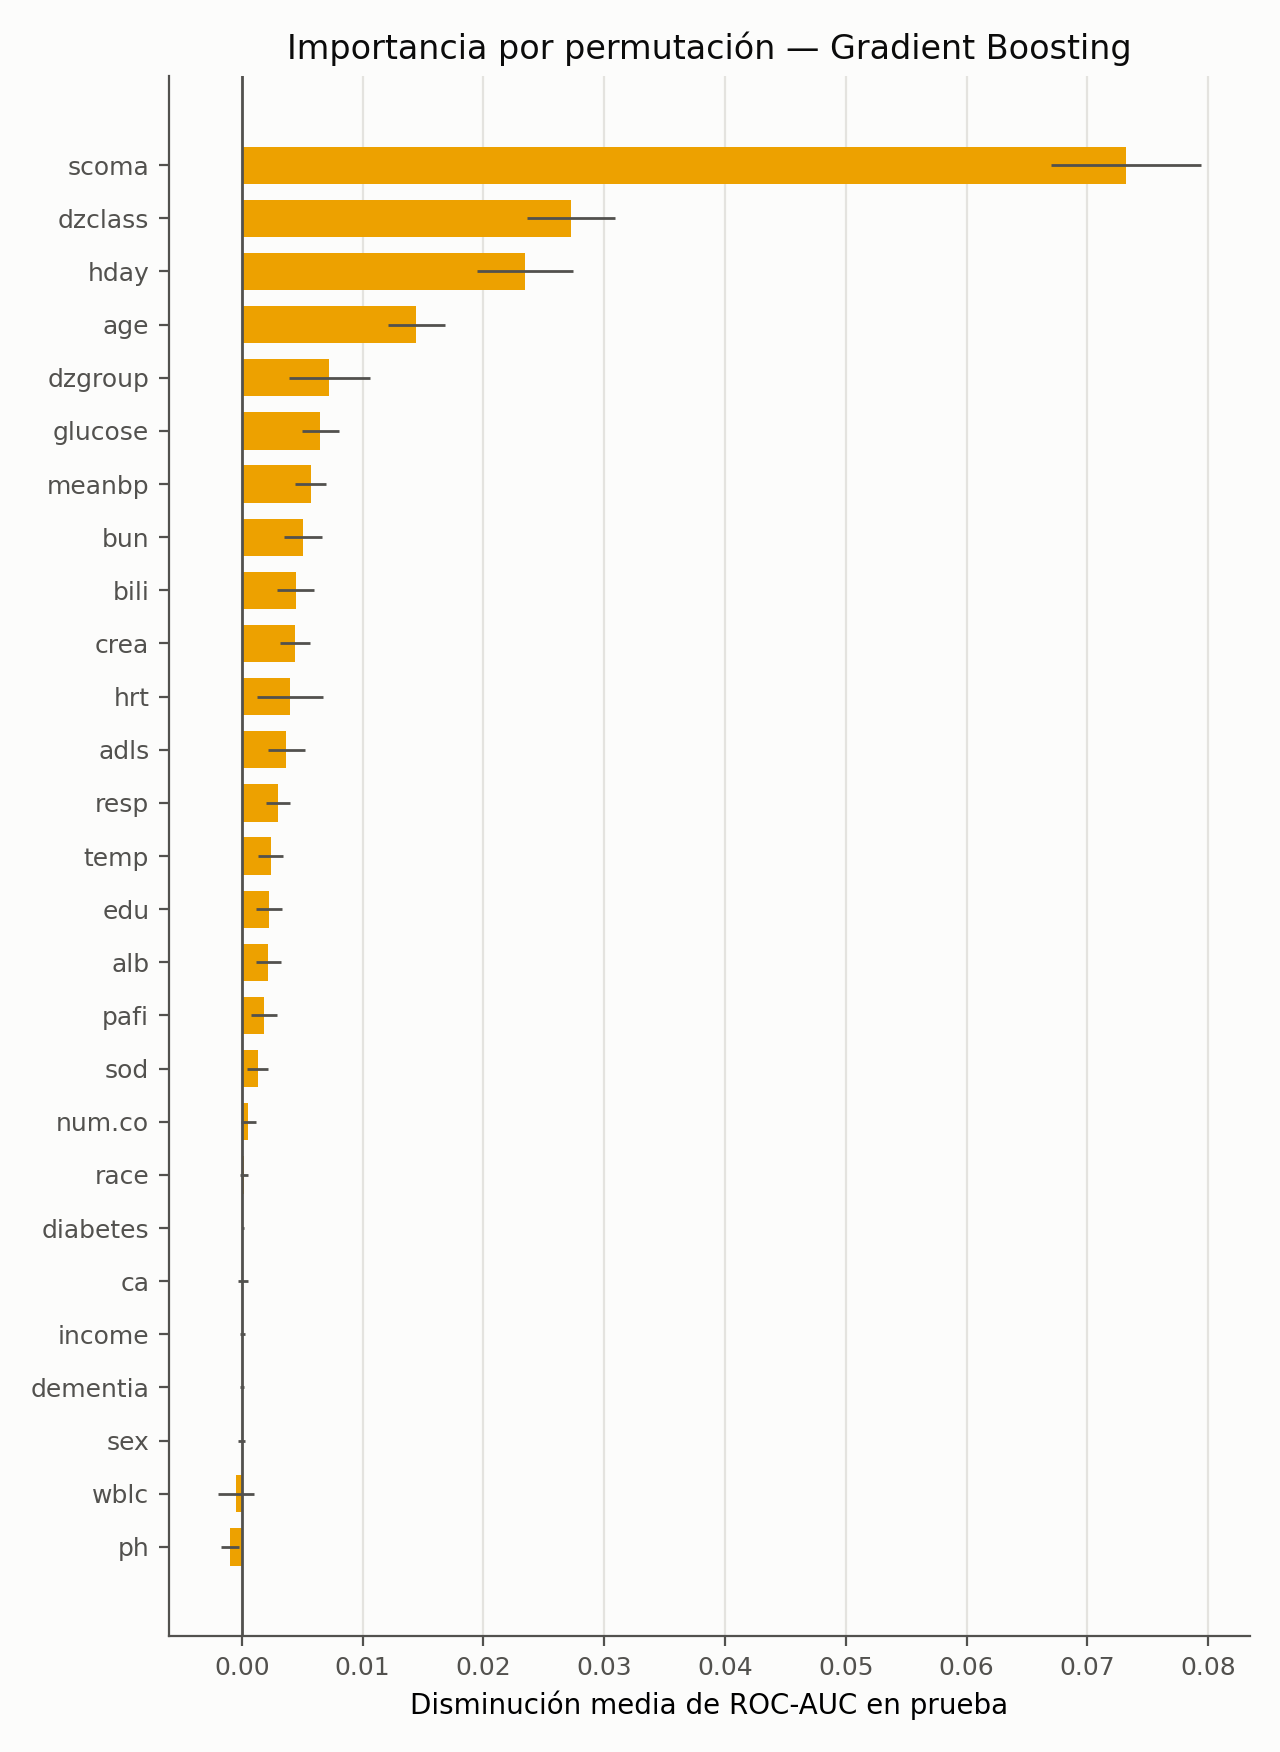

,feature,group,importance_mean,importance_std
0,scoma,physiological,0.0732,0.0062
1,dzclass,clinical,0.0272,0.0036
2,hday,clinical,0.0235,0.0040
3,age,demographic,0.0144,0.0023
4,dzgroup,clinical,0.0072,0.0033
5,glucose,physiological,0.0065,0.0015
6,meanbp,physiological,0.0057,0.0013
7,bun,physiological,0.0051,0.0016
8,bili,physiological,0.0045,0.0015
9,crea,physiological,0.0044,0.0013


Importancia total por grupo (suma de caídas de AUC):


group
physiological    0.1125
clinical         0.0623
demographic      0.0169
Name: importance_mean, dtype: float64

In [12]:
display(Image(FIGURES / "p2_permutation_importance.png", width=560))
perm = pd.read_csv(TABLES / "p2_permutation_importance.csv")
display(perm.head(12))
print("Importancia total por grupo (suma de caídas de AUC):")
perm.groupby("group")["importance_mean"].sum().sort_values(ascending=False)

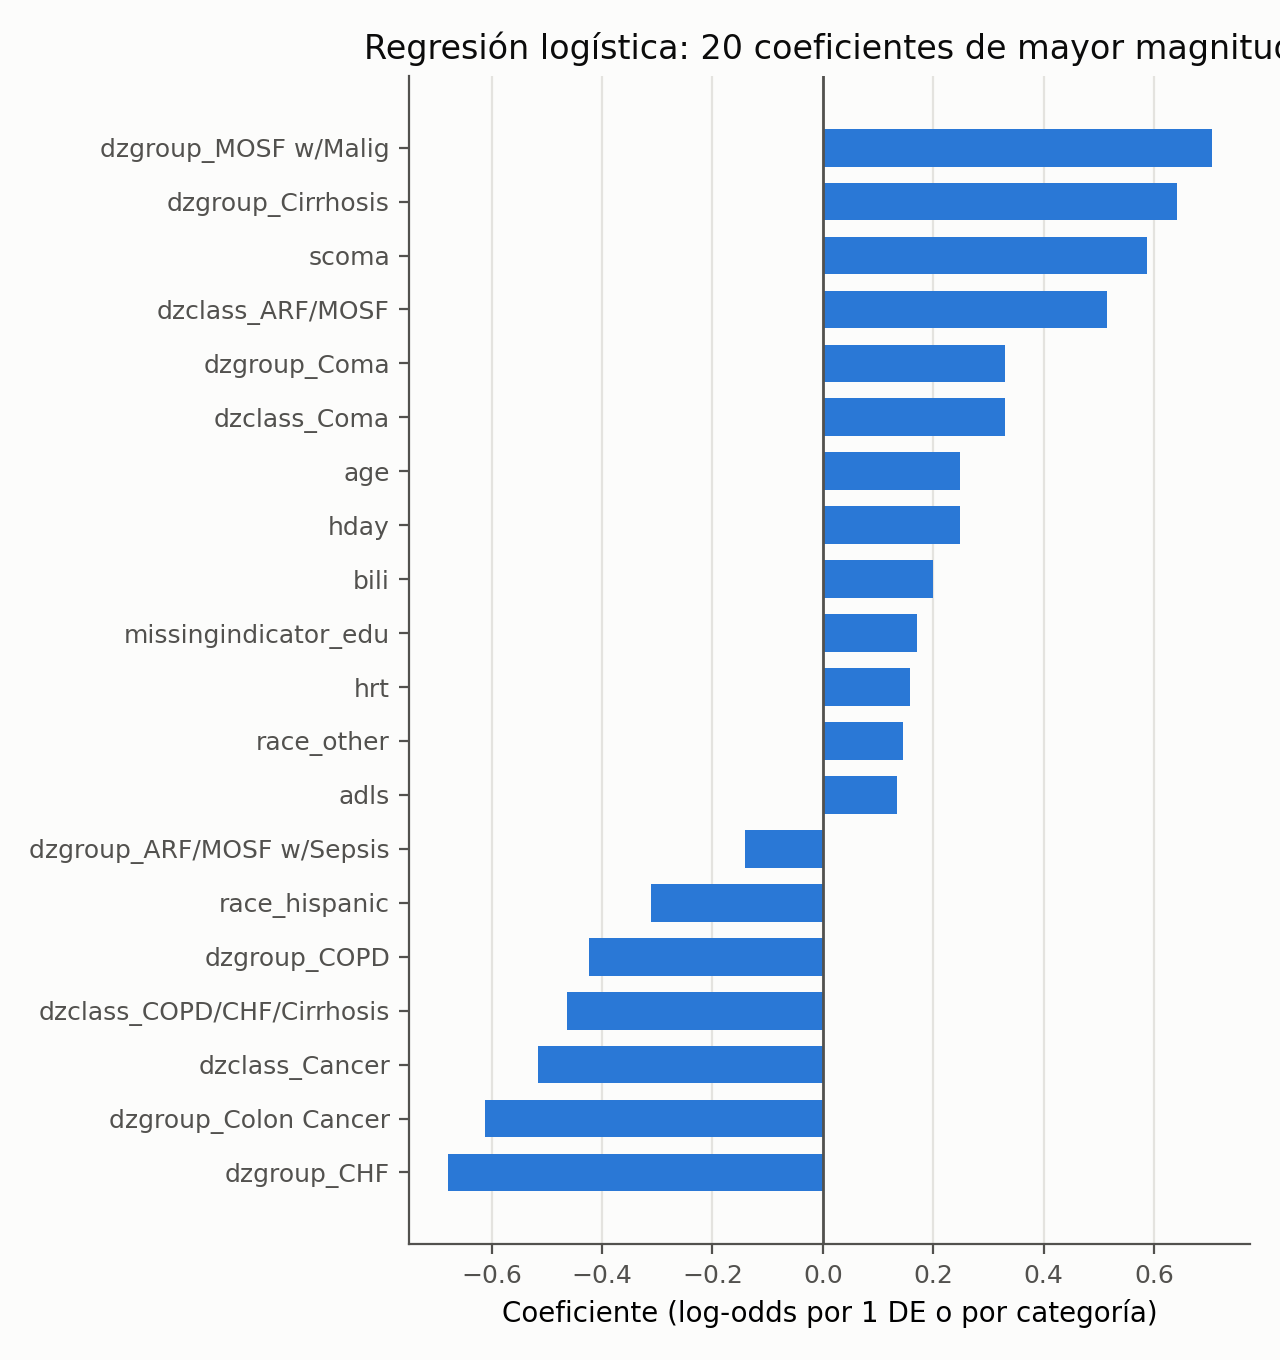

,feature,coef,odds_ratio,abs_coef
0,dzgroup_MOSF w/Malig,0.7042,2.0222,0.7042
1,dzgroup_CHF,-0.6796,0.5068,0.6796
2,dzgroup_Cirrhosis,0.6413,1.8989,0.6413
3,dzgroup_Colon Cancer,-0.6123,0.5421,0.6123
4,scoma,0.5860,1.7968,0.5860
5,dzclass_Cancer,-0.5164,0.5967,0.5164
6,dzclass_ARF/MOSF,0.5144,1.6726,0.5144
7,dzclass_COPD/CHF/Cirrhosis,-0.4627,0.6296,0.4627
8,dzgroup_COPD,-0.4243,0.6542,0.4243
9,dzgroup_Coma,0.3292,1.3899,0.3292


In [13]:
display(Image(FIGURES / "p2_logreg_coefficients.png", width=560))
pd.read_csv(TABLES / "p2_logreg_coefficients.csv").head(15)

Los coeficientes de la logística se interpretan como log-odds: $e^{w_j}$
multiplica los odds de fallecer por cada desviación estándar adicional de $x_j$
(o frente a la categoría omitida), manteniendo el resto constante. Son
asociaciones predictivas, **no** efectos causales.

## 9. Análisis de errores y subgrupos (modelo final, umbral τ)

In [14]:
sub = pd.read_csv(TABLES / "p2_subgroup_performance.csv")
sub

,variable,group,n,prevalence,mean_predicted,roc_auc,recall,precision,fnr,fpr
0,dzgroup,ARF/MOSF w/Sepsis,711,0.3601,0.3420,0.7347,0.7031,0.5099,0.2969,0.3802
1,dzgroup,CHF,272,0.0588,0.0662,0.7693,0.1875,0.7500,0.8125,0.0039
2,dzgroup,COPD,201,0.1343,0.1153,0.7822,0.2222,0.4615,0.7778,0.0402
3,dzgroup,Lung Cancer,170,0.0706,0.1025,0.7748,0.1667,0.6667,0.8333,0.0063
4,dzgroup,MOSF w/Malig,137,0.4964,0.5119,0.7688,0.9706,0.5323,0.0294,0.8406
5,dzgroup,Coma,119,0.5714,0.5737,0.6941,0.9265,0.6117,0.0735,0.7843
6,dzgroup,Cirrhosis,112,0.1696,0.1962,0.8076,0.5263,0.5556,0.4737,0.0860
7,dzgroup,Colon Cancer,99,0.0606,0.0670,0.9462,0.3333,1.0000,0.6667,0.0000
8,sex,male,1020,0.2706,0.2538,0.8247,0.6775,0.5484,0.3225,0.2070
9,sex,female,801,0.2447,0.2621,0.8489,0.7398,0.5197,0.2602,0.2215


In [15]:
prof = pd.read_csv(TABLES / "p2_error_profile.csv", index_col=0)
prof

,TP,FN,FP,TN,missing_pct_TP,missing_pct_FN
age,66.8885,66.6460,64.1790,63.4390,0.0000,0.0000
num.co,1.0000,2.0000,1.0000,2.0000,0.0000,0.0000
edu,12.0000,12.0000,12.0000,12.0000,29.2169,15.7143
scoma,37.0000,0.0000,9.0000,0.0000,0.0000,0.0000
hday,5.0000,1.0000,4.0000,1.0000,0.0000,0.0000
diabetes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
dementia,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
meanbp,69.0000,77.0000,73.0000,80.0000,0.0000,0.0000
wblc,11.8984,10.5498,12.5000,9.7988,1.8072,2.8571
hrt,110.0000,90.0000,109.0000,87.0000,0.0000,0.0000


## 10. Extensiones: imputación, recalibración y umbrales

Generadas por `python scripts/run_p2_extensions.py`. Todas las decisiones se toman en
entrenamiento (CV / predicciones out-of-fold); el test solo reporta.

**A. Imputación.** Mediana vs. valores normales de SUPPORT, KNN (k = 10) e
iterativa (MICE). Regla fijada de antemano: abandonar la mediana solo si la
mejora en AUC de CV supera 0.005 y 2 errores estándar de la diferencia pareada.

In [16]:
if RUN_EXPERIMENT or not (ROOT / "results" / "p2x_run_metadata.json").exists():
    import run_p2_extensions
    run_p2_extensions.main()
ext_meta = json.loads((ROOT / "results" / "p2x_run_metadata.json").read_text(encoding="utf-8"))
print("Imputación elegida:", ext_meta["imputation_selected"])
pd.read_csv(TABLES / "p2x_imputation_comparison.csv")

Imputación elegida: {'logreg': 'median', 'tree': 'median', 'rf': 'median', 'gboost': 'median'}


,model,imputation,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean,cv_brier_mean,cv_auc_diff_vs_median,cv_auc_diff_se,selected,test_roc_auc
0,logreg,median,0.8044,0.0074,0.6090,0.1786,0.0000e+00,0.0000e+00,True,0.8199
1,logreg,normal,0.8043,0.0074,0.6090,0.1786,-8.2996e-06,2.6208e-05,False,0.8199
2,logreg,knn,0.8048,0.0066,0.6089,0.1787,4.4783e-04,6.9629e-04,False,0.8217
3,logreg,iterative,0.8041,0.0067,0.6089,0.1790,-2.9310e-04,5.2738e-04,False,0.8210
4,tree,median,0.7813,0.0120,0.5581,0.1540,0.0000e+00,0.0000e+00,True,0.7992
5,tree,normal,0.7789,0.0166,0.5561,0.1546,-2.3699e-03,2.7403e-03,False,0.8051
6,tree,knn,0.7815,0.0110,0.5581,0.1539,1.8207e-04,1.5150e-03,False,0.8056
7,tree,iterative,0.7748,0.0119,0.5577,0.1552,-6.4401e-03,2.9477e-03,False,0.7985
8,rf,median,0.8184,0.0098,0.6265,0.1642,0.0000e+00,0.0000e+00,True,0.8322
9,rf,normal,0.8198,0.0102,0.6291,0.1637,1.4886e-03,4.0783e-04,False,0.8328


**B. Recalibración** (Platt / isotónica con `CalibratedClassifierCV`, 5 folds
dentro de train). El método se elige por el menor Brier *out-of-fold*.

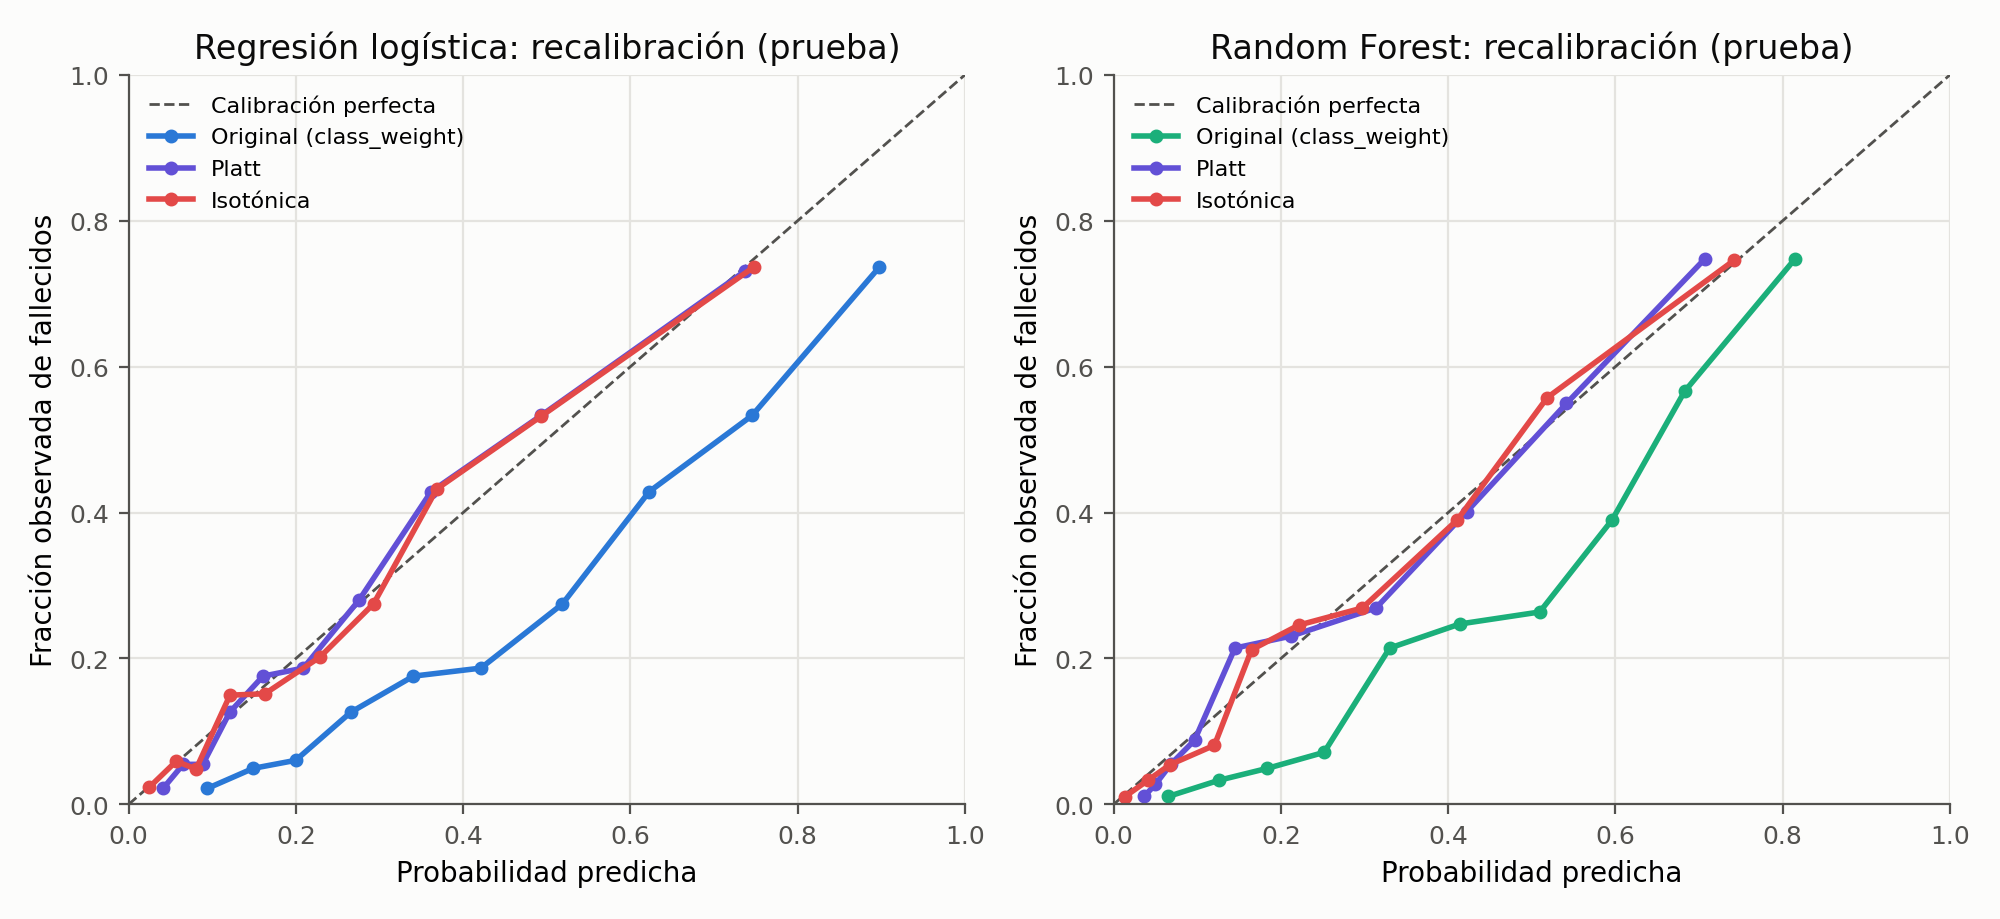

,model,calibration,split,roc_auc,average_precision,brier,log_loss,ece,selected
0,logreg,none,train_oof,0.8042,0.6056,0.1786,0.5372,0.1699,False
1,logreg,none,test,0.8199,0.6294,0.1710,0.5186,0.1660,False
2,logreg,sigmoid,train_oof,0.8042,0.6054,0.1457,0.4507,0.0103,True
3,logreg,sigmoid,test,0.8199,0.6293,0.1412,0.4380,0.0241,True
4,logreg,isotonic,train_oof,0.8034,0.6037,0.1459,0.4514,0.0075,False
5,logreg,isotonic,test,0.8179,0.6263,0.1417,0.4388,0.0197,False
6,rf,none,train_oof,0.8175,0.6225,0.1642,0.4950,0.1376,False
7,rf,none,test,0.8322,0.6412,0.1596,0.4844,0.1397,False
8,rf,sigmoid,train_oof,0.8169,0.6225,0.1427,0.4405,0.0161,False
9,rf,sigmoid,test,0.8304,0.6370,0.1391,0.4294,0.0347,False


In [17]:
display(Image(FIGURES / "p2x_recalibration.png", width=900))
pd.read_csv(TABLES / "p2x_calibration_comparison.csv")

**C. Umbral con costos explícitos**: $C_{FP}=1$, $C_{FN}=R$. Con probabilidades
calibradas, la regla de Bayes da $\tau^*=1/(1+R)$. No hay un $R$ clínicamente
validado, por lo que se presenta un análisis de sensibilidad.

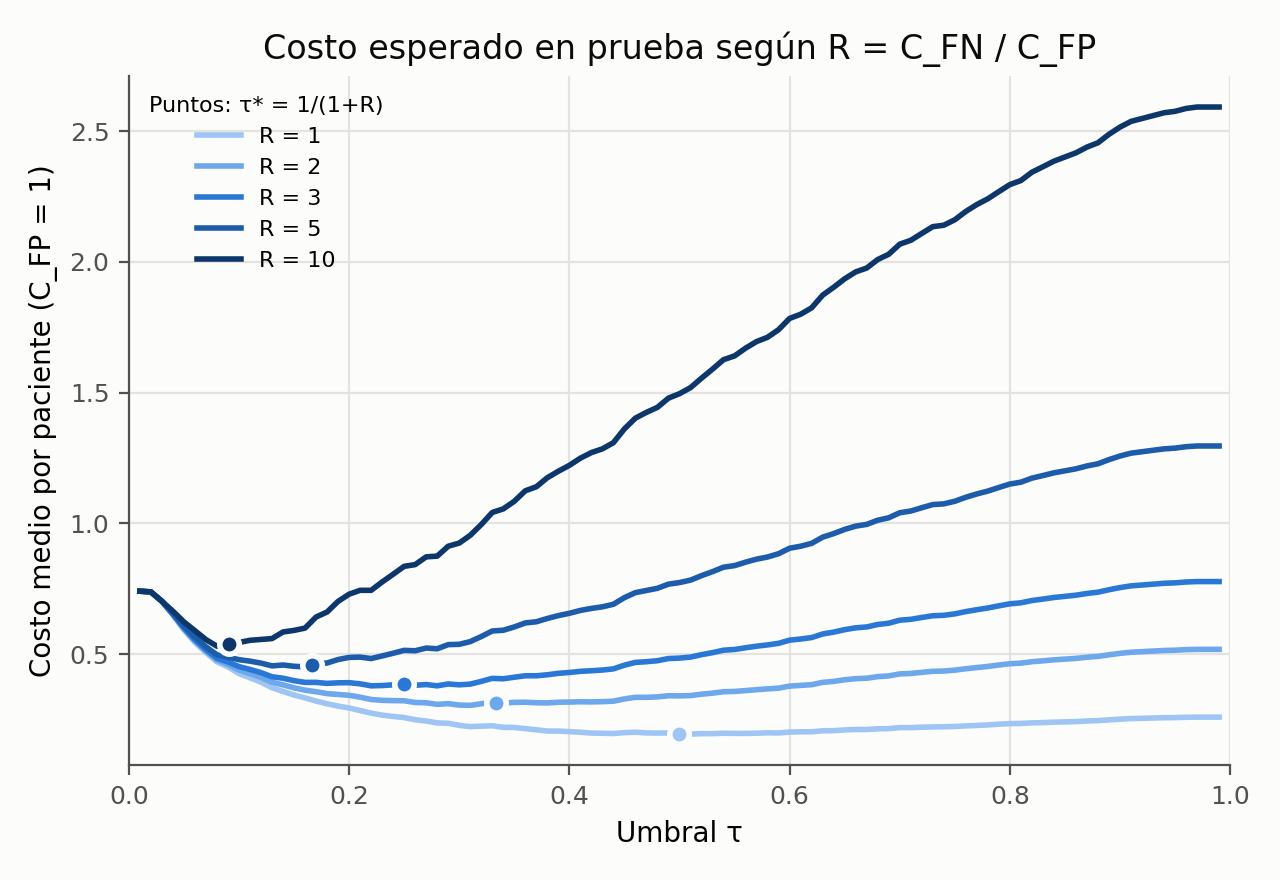

,cost_ratio_R,rule,threshold,test_cost_per_patient,cost_treat_none,cost_treat_all,recall,precision,specificity,f1,TP,FP,FN,TN
0,1,bayes_1/(1+R),0.5000,0.1960,0.2592,0.7408,0.4428,0.6898,0.9303,0.5394,209,94,263,1255
1,1,empirical_oof,0.5500,0.1971,0.2592,0.7408,0.3814,0.7287,0.9503,0.5007,180,67,292,1282
4,2,bayes_1/(1+R),0.3333,0.3147,0.5184,0.7408,0.6504,0.5582,0.8199,0.6008,307,243,165,1106
5,2,empirical_oof,0.3000,0.3053,0.5184,0.7408,0.7013,0.5471,0.7969,0.6147,331,274,141,1075
8,3,bayes_1/(1+R),0.2500,0.3861,0.7776,0.7408,0.7521,0.5021,0.7391,0.6022,355,352,117,997
9,3,empirical_oof,0.2500,0.3861,0.7776,0.7408,0.7521,0.5021,0.7391,0.6022,355,352,117,997
12,5,bayes_1/(1+R),0.1667,0.4591,1.2960,0.7408,0.8708,0.4363,0.6064,0.5813,411,531,61,818
13,5,empirical_oof,0.1600,0.4514,1.2960,0.7408,0.8856,0.4309,0.5908,0.5798,418,552,54,797
16,10,bayes_1/(1+R),0.0909,0.5387,2.5920,0.7408,0.9619,0.3618,0.4062,0.5258,454,801,18,548
17,10,empirical_oof,0.0800,0.5305,2.5920,0.7408,0.9746,0.3522,0.3729,0.5174,460,846,12,503


In [18]:
display(Image(FIGURES / "p2x_cost_curves.png", width=520))
c = pd.read_csv(TABLES / "p2x_cost_thresholds.csv")
c[c.rule.isin(["bayes_1/(1+R)", "empirical_oof"])]

**D. Umbral global vs. umbral por grupo diagnóstico** (`dzgroup`).

In [19]:
display(pd.read_csv(TABLES / "p2x_group_thresholds_overall.csv"))
pd.read_csv(TABLES / "p2x_group_thresholds_by_group.csv").pivot(
    index="dzgroup", columns="rule", values=["threshold", "fnr", "fpr"]).round(3)

,rule,TP,FP,FN,TN,recall,precision,specificity,f1,cost_per_patient_R3
0,global_max_f1,332,288,140,1061,0.7034,0.5355,0.7865,0.6081,0.3888
1,global_cost_R3,355,352,117,997,0.7521,0.5021,0.7391,0.6022,0.3861
2,group_max_f1,348,348,124,1001,0.7373,0.5000,0.7420,0.5959,0.3954
3,group_cost_R3,354,348,118,1001,0.7500,0.5043,0.7420,0.6031,0.3855


threshold                                           \
rule              global_cost_R3 global_max_f1 group_cost_R3 group_max_f1   
dzgroup                                                                     
ARF/MOSF w/Sepsis           0.25         0.293          0.26        0.274   
CHF                         0.25         0.293          0.21        0.198   
COPD                        0.25         0.293          0.37        0.129   
Cirrhosis                   0.25         0.293          0.22        0.258   
Colon Cancer                0.25         0.293          0.19        0.158   
Coma                        0.25         0.293          0.16        0.421   
Lung Cancer                 0.25         0.293          0.16        0.157   
MOSF w/Malig                0.25         0.293          0.30        0.304   

                             fnr                                           \
rule              global_cost_R3 global_max_f1 group_cost_R3 group_max_f1   
dzgroup                                                                     
ARF/MOSF w/Sepsis          0.227         0.297         0.238        0.270   
CHF                        0.812         0.812         0.812        0.812   
COPD                       0.741         0.778         0.889        0.370   
Cirrhosis                  0.421         0.474         0.421        0.421   
Colon Cancer               0.667         0.667         0.667        0.500   
Coma                       0.029         0.074         0.000        0.191   
Lung Cancer                0.833         0.833         0.500        0.500   
MOSF w/Malig               0.029         0.029         0.029        0.029   

                             fpr                                           
rule              global_cost_R3 global_max_f1 group_cost_R3 group_max_f1  
dzgroup                                                                    
ARF/MOSF w/Sepsis          0.477         0.380         0.444        0.413  
CHF                        0.008         0.004         0.012        0.016  
COPD                       0.052         0.040         0.023        0.224  
Cirrhosis                  0.118         0.086         0.183        0.108  
Colon Cancer               0.011         0.000         0.011        0.022  
Coma                       0.824         0.784         0.941        0.569  
Lung Cancer                0.025         0.006         0.101        0.120  
MOSF w/Malig               0.957         0.841         0.826        0.826

## 11. Limitaciones

* **Temporalidad**: las mediciones fisiológicas corresponden al día 3 del estudio,
  no necesariamente de la hospitalización (`hday` > 1 en 3157 pacientes); 138
  fallecidos tienen `slos = 3` y `d.time = 3`, por lo que parte de sus mediciones
  pueden estar muy próximas al desenlace. Es una clasificación **retrospectiva**,
  no una validación clínica prospectiva (ver `results/tables/temporal_audit.csv`).
* **Faltantes**: glucosa, BUN y albúmina superan 35–50 % de ausencia; la
  imputación por mediana asume que el valor típico es razonable.
* **Validez externa**: SUPPORT (1989–1994, 5 hospitales de EE. UU., pacientes
  gravemente enfermos) no representa la práctica ni la población actual.
* **Equidad**: grupos pequeños (p. ej. `race = asian/other`) tienen métricas muy
  inestables; las diferencias de FNR/FPR por subgrupo deben revisarse antes de
  cualquier uso.
* El umbral óptimo-F1 no incorpora costos clínicos reales de FN vs FP.